# Nhận dạng cảm xúc khuôn mặt (FER2013) → Emoji

**BTL cuối kỳ Trí tuệ nhân tạo – Chủ đề 3:** phân loại trạng thái cảm xúc khuôn mặt (đầu vào là ảnh, đầu ra là emoji).

Notebook này dùng **một mô hình duy nhất**: `emotion_model_ensemble_final.keras` – ensemble gồm hai mô hình con (`emotion_model_superior` và `v3_model`), ghép bằng **trung bình xác suất**. Cả hai mô hình con được huấn luyện trên FER2013. Notebook **không huấn luyện lại**, chỉ nạp mô hình đã có để đánh giá và demo.

| Phần | Nội dung |
|---|---|
| 0 | Cài đặt, import, cấu hình |
| 1 | Nạp mô hình ensemble |
| 2 | Dữ liệu FER2013 |
| 3 | Đánh giá trên tập test của FER2013 (ensemble và từng mô hình con) |
| 4 | Demo: kiểm tra đầu vào, detect mặt, dự đoán ra emoji |
| 5 | Ảnh test cho báo cáo (10–15 ảnh) |

**Lưu ý:** tiền xử lý lúc demo phải **giống hệt** lúc đánh giá (chuyển xám → cắt mặt → resize 48x48 → chia 255), nên notebook dùng **một hàm duy nhất** `preprocess_gray_face()` ở mọi nơi.

## 0. Cài đặt, import và cấu hình

In [1]:
# Bỏ dấu # ở dòng dưới và chạy nếu chưa cài thư viện
# %pip install tensorflow opencv-python numpy pandas matplotlib scikit-learn ipywidgets pillow

In [2]:
import os
import json
import shutil
import tempfile
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score, f1_score,
)
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ================== CẤU HÌNH CHUNG ==================
IMG_SIZE = 48          # FER2013: ảnh xám 48x48, 1 kênh
NUM_CLASSES = 7

# Thứ tự nhãn của FER2013 (0..6)
LABELS = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
LABELS_VI = ['Giận', 'Ghê tởm', 'Sợ', 'Vui', 'Buồn', 'Ngạc nhiên', 'Bình thường']
EMOJIS = ['😠', '🤢', '😨', '😄', '😢', '😮', '😐']

# ----- Mô hình và dữ liệu -----
MODEL_PATH = 'emotion_model_ensemble_final.keras'
CSV_PATH = 'fer2013.csv'
USE_TTA = True          # True: dự đoán thêm ảnh lật ngang rồi lấy trung bình (Test-Time Augmentation)

# ----- Ngưỡng kiểm tra ảnh upload (demo) -----
MIN_FACE_SIZE = 100     # cạnh nhỏ nhất của vùng mặt (px)
MAX_FILE_MB = 20
DARK_THRESHOLD = 60     # độ sáng trung bình của VÙNG MẶT
BRIGHT_THRESHOLD = 200
BLUR_THRESHOLD = 60     # phương sai Laplacian của vùng mặt đã resize về 96x96
LOW_CONFIDENCE = 0.40
ALLOWED_EXT = ('.jpg', '.jpeg', '.png')
DETECT_MAX_SIDE = 800   # thu nhỏ ảnh lớn trước khi detect mặt (nhanh hơn và ít bắt nhầm hơn)
FACE_MARGIN_X, FACE_MARGIN_Y = 0.10, 0.12   # mở rộng vùng cắt quanh mặt

# ----- Ảnh test cho báo cáo -----
TEST_DIR = 'test_images'
TEST_CSV = 'test_labels.csv'

I0000 00:00:1795226945.695823    1665 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795226945.834142    1665 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795226947.318929    1665 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Hàm tiền xử lý dùng chung

Đầu vào là ảnh **xám** (đã cắt mặt), đầu ra là mảng `(48, 48, 1)` float32 trong khoảng [0, 1]. Mô hình tự phóng lên 96x96 và nhân bản thành 3 kênh bên trong (lớp `Resizing`, `Concatenate`, `Rescaling`), nên bên ngoài không cần làm thêm.

In [3]:
def preprocess_gray_face(gray_face):
    '''Ảnh xám bất kỳ kích thước -> (48, 48, 1) float32 trong [0, 1].'''
    face = cv2.resize(gray_face, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    face = face.astype('float32') / 255.0
    return face[..., np.newaxis]

## 1. Nạp mô hình ensemble

File `.keras` lưu bằng phiên bản Keras mới có thể chứa cấu hình `compile` (hàm loss) mà phiên bản Keras cũ hơn không đọc được. Vì mô hình chỉ dùng để suy luận nên ta **bỏ phần `compile`** khi nạp; hàm `load_ensemble()` thử nạp thẳng trước, nếu lỗi thì tự bỏ `compile_config` rồi nạp lại.

In [4]:
def _strip_compile_config(obj):
    if isinstance(obj, dict):
        obj.pop('compile_config', None)
        for v in obj.values():
            _strip_compile_config(v)
    elif isinstance(obj, list):
        for v in obj:
            _strip_compile_config(v)


def load_ensemble(path):
    '''Nạp mô hình chỉ để suy luận (không compile).'''
    try:
        return tf.keras.models.load_model(path, compile=False)
    except Exception as first_error:
        print('Nạp trực tiếp lỗi, thử bỏ compile_config:', str(first_error)[:120])
    tmp = os.path.join(tempfile.gettempdir(), 'ensemble_no_compile.keras')
    with zipfile.ZipFile(path) as zin, zipfile.ZipFile(tmp, 'w', zipfile.ZIP_STORED) as zout:
        for name in zin.namelist():
            data = zin.read(name)
            if name == 'config.json':
                cfg = json.loads(data)
                _strip_compile_config(cfg)
                data = json.dumps(cfg).encode()
            zout.writestr(name, data)
    return tf.keras.models.load_model(tmp, compile=False, safe_mode=False)


assert os.path.exists(MODEL_PATH), 'Không thấy ' + MODEL_PATH + ' (đặt cạnh notebook hoặc sửa MODEL_PATH).'
model = load_ensemble(MODEL_PATH)
sub_models = [l for l in model.layers if isinstance(l, tf.keras.Model)]

print('TensorFlow', tf.__version__, '| OpenCV', cv2.__version__)
print('Mô hình:', model.name, '| đầu vào', model.input_shape, '| đầu ra', model.output_shape)
print('Tổng tham số: {:,}'.format(model.count_params()))
for m in sub_models:
    print(' - mô hình con:', m.name, '({:,} tham số)'.format(m.count_params()))

Nạp trực tiếp lỗi, thử bỏ compile_config: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that 


TensorFlow 2.21.0 | OpenCV 5.0.0
Mô hình: emotion_ensemble_clean | đầu vào (None, 48, 48, 1) | đầu ra (None, 7)
Tổng tham số: 6,660,238
 - mô hình con: emotion_model_superior (3,577,671 tham số)
 - mô hình con: v3_model (3,082,567 tham số)


## 2. Dữ liệu FER2013

FER2013: ảnh xám, 1 kênh, 48x48 px, khoảng 35 nghìn ảnh, 7 nhãn. Đặt `fer2013.csv` cạnh notebook (hoặc sửa `CSV_PATH`).

Quy ước: **Training** dùng để học, **PublicTest** là tập validation, **PrivateTest** là tập test cuối cùng. Các số liệu đánh giá trong báo cáo lấy trên **PrivateTest**.

Kích thước bảng: (35887, 3)
Usage
Training       28709
PublicTest      3589
PrivateTest     3589


Val: (3589, 48, 48, 1) | Test: (3589, 48, 48, 1)


emotion,Angry,Disgust,Fear,Happy,Sad,Surprise,Neutral
Usage,,,,,,,
PrivateTest,491,55,528,879,594,416,626
PublicTest,467,56,496,895,653,415,607
Training,3995,436,4097,7215,4830,3171,4965


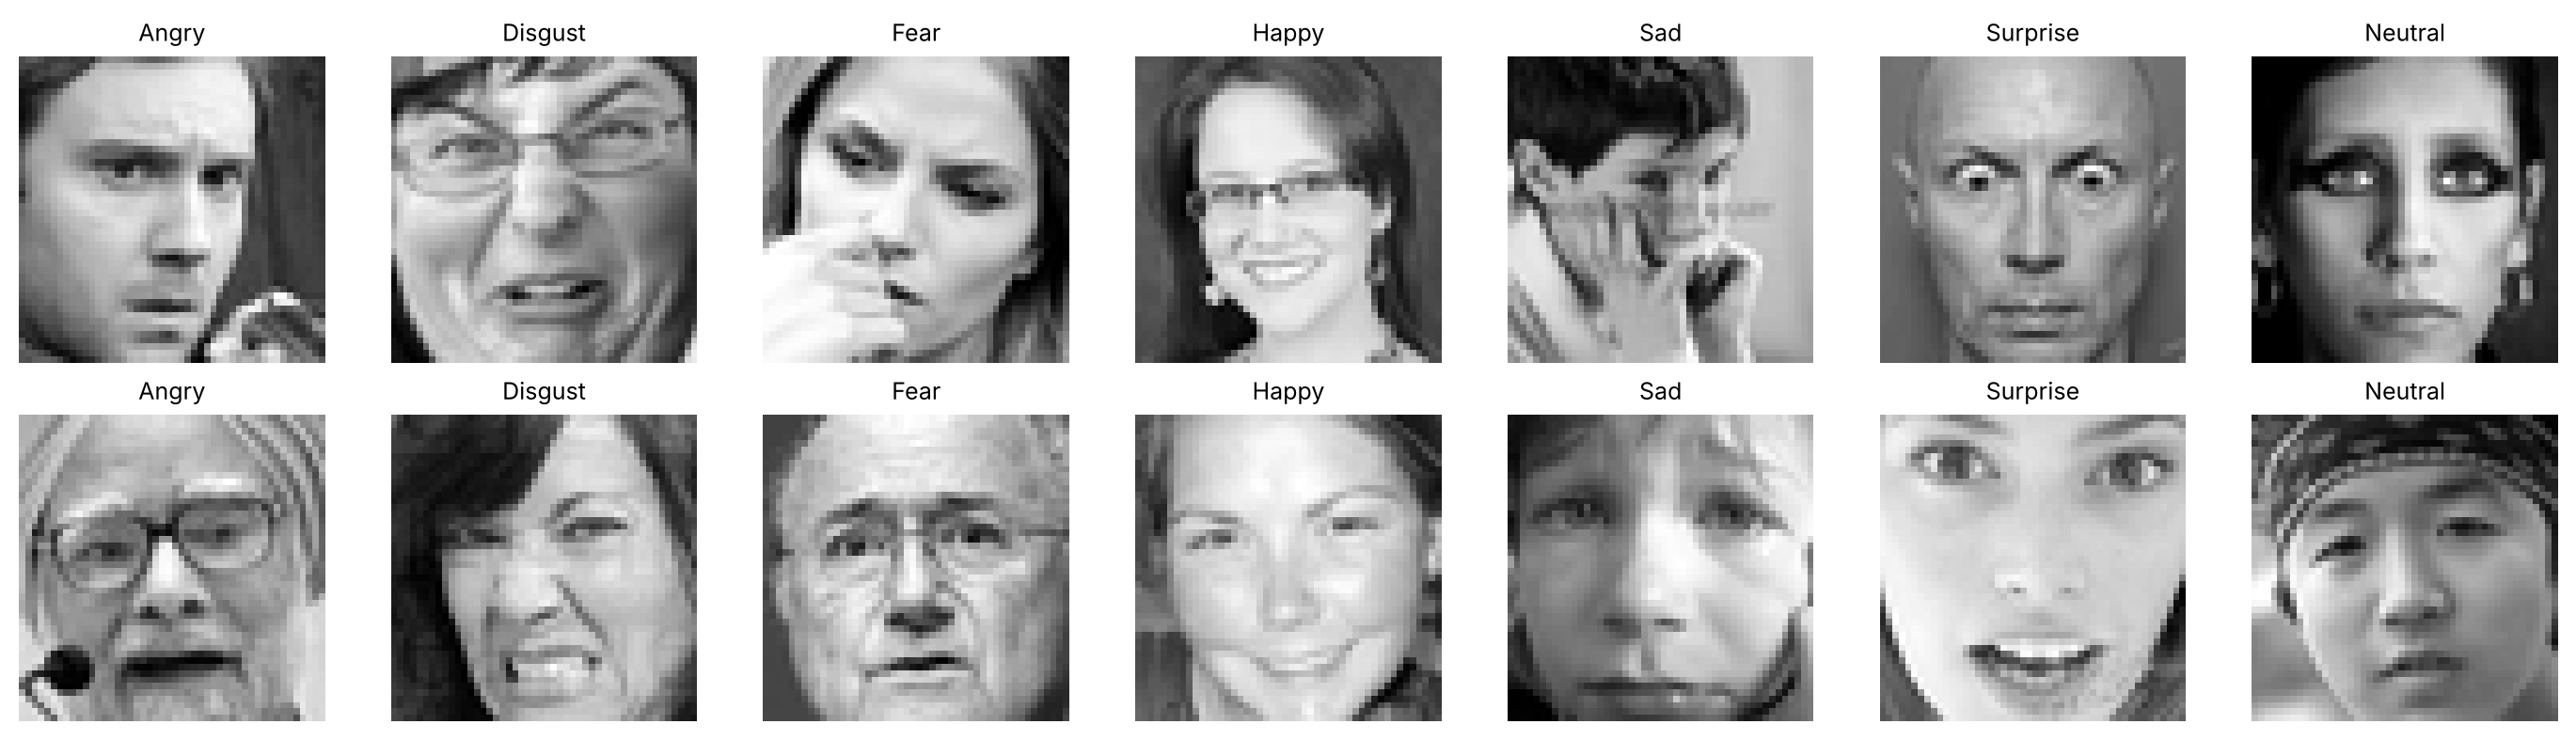

In [5]:
df = pd.read_csv(CSV_PATH)
print('Kích thước bảng:', df.shape)
print(df['Usage'].value_counts().to_string())

def pixels_to_array(pixel_string):
    return np.array(pixel_string.split(), dtype='uint8').reshape(IMG_SIZE, IMG_SIZE)

def get_split(usage):
    part = df[df['Usage'] == usage]
    X = np.stack([preprocess_gray_face(pixels_to_array(p)) for p in part['pixels']])
    return X, part['emotion'].values.astype('int64')

X_val, y_val = get_split('PublicTest')
X_test, y_test = get_split('PrivateTest')
print('Val:', X_val.shape, '| Test:', X_test.shape)

# Phân bố nhãn theo từng tập
dist = pd.crosstab(df['Usage'], df['emotion']).rename(columns=dict(enumerate(LABELS)))
display(dist)
fig, axes = plt.subplots(2, 7, figsize=(14, 4))
train_part = df[df['Usage'] == 'Training']
for c in range(NUM_CLASSES):
    for r, p in enumerate(train_part[train_part['emotion'] == c]['pixels'].iloc[:2]):
        axes[r, c].imshow(pixels_to_array(p), cmap='gray')
        axes[r, c].set_title(LABELS[c], fontsize=9)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

## 3. Đánh giá trên tập test của FER2013

Ta đo **từng mô hình con** và **ensemble**, có và không có flip-TTA (dự đoán thêm ảnh lật ngang rồi lấy trung bình). Xác suất của ensemble được tính từ hai mô hình con (đúng bằng lớp `Average` trong mô hình) và có một bước kiểm tra để chắc chắn khớp với đầu ra thật của mô hình.

,Accuracy,Accuracy + flip-TTA,Macro-F1 + flip-TTA
Mô hình,,,
emotion_model_superior,57.3%,57.8%,57.9%
v3_model,56.5%,57.9%,57.3%
ENSEMBLE,60.0%,60.9%,60.6%


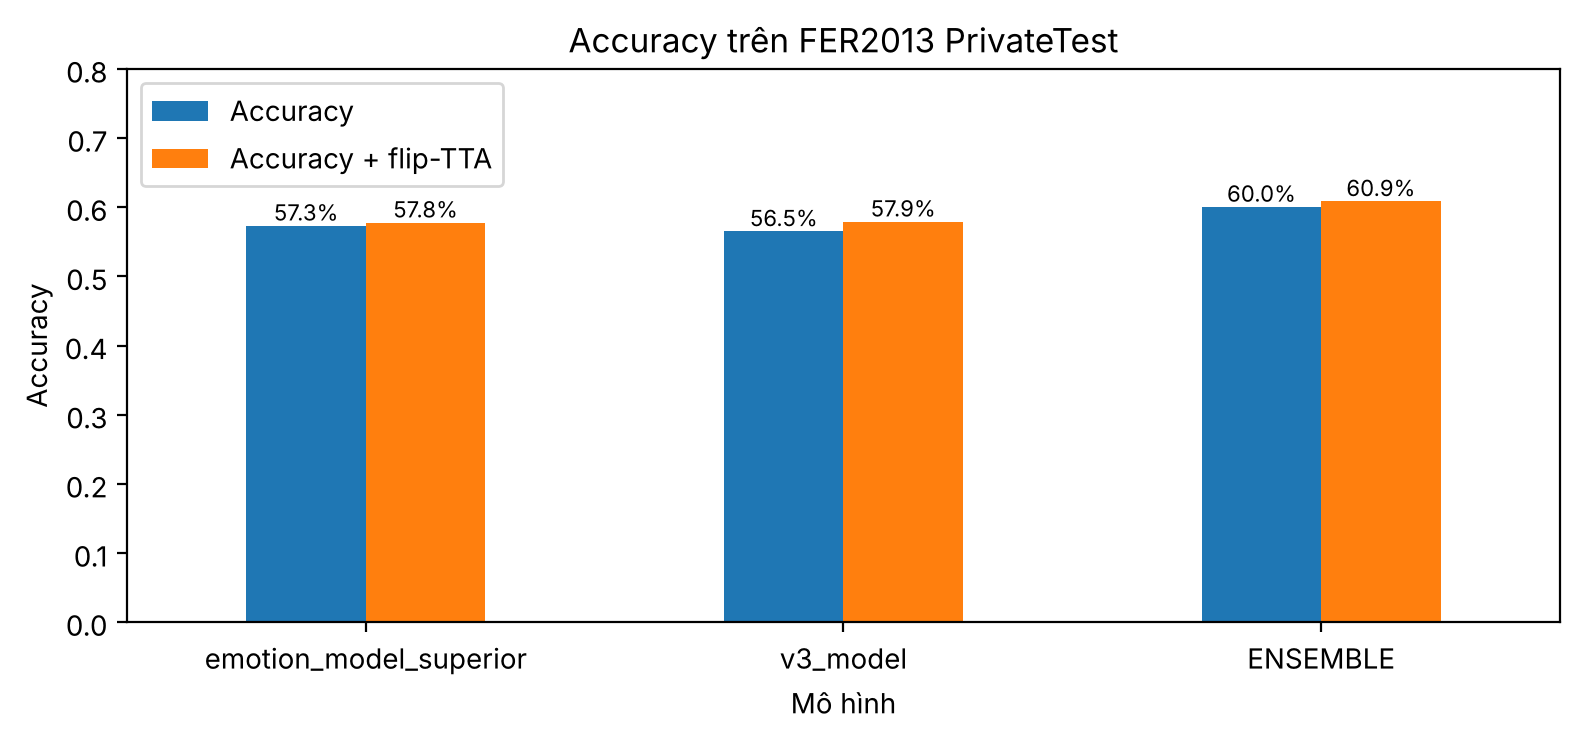

In [6]:
def predict_probs(m, X, flip=False, batch_size=128):
    if flip:
        X = X[:, :, ::-1, :]
    return m.predict(X, batch_size=batch_size, verbose=0)

# Xác suất của từng mô hình con (ảnh gốc và ảnh lật)
probs = {}
for m in sub_models:
    probs[m.name] = {'orig': predict_probs(m, X_test), 'flip': predict_probs(m, X_test, flip=True)}

# Ensemble = trung bình xác suất của các mô hình con
names = [m.name for m in sub_models]
probs['ENSEMBLE'] = {k: np.mean([probs[n][k] for n in names], axis=0) for k in ('orig', 'flip')}

# Kiểm tra: khớp với đầu ra thật của mô hình ensemble
check = model.predict(X_test[:256], verbose=0)
assert np.allclose(check, probs['ENSEMBLE']['orig'][:256], atol=1e-4), 'Ensemble tính tay không khớp mô hình'

rows = []
for name, p in probs.items():
    p_tta = (p['orig'] + p['flip']) / 2.0
    rows.append({
        'Mô hình': name,
        'Accuracy': np.mean(p['orig'].argmax(1) == y_test),
        'Accuracy + flip-TTA': np.mean(p_tta.argmax(1) == y_test),
        'Macro-F1 + flip-TTA': f1_score(y_test, p_tta.argmax(1), average='macro'),
    })
summary = pd.DataFrame(rows).set_index('Mô hình')
display(summary.style.format('{:.1%}'))

ax = summary[['Accuracy', 'Accuracy + flip-TTA']].plot.bar(figsize=(8, 3.8), rot=0, ylim=(0, 0.8))
ax.set_title('Accuracy trên FER2013 PrivateTest'); ax.set_ylabel('Accuracy')
for c in ax.containers:
    ax.bar_label(c, labels=['{:.1%}'.format(v) for v in c.datavalues], fontsize=8)
plt.tight_layout(); plt.show()

Cấu hình: ensemble + flip-TTA
Test accuracy: 0.6085
              precision    recall  f1-score   support

       Angry      0.540     0.473     0.504       491
     Disgust      0.838     0.564     0.674        55
        Fear      0.538     0.434     0.480       528
       Happy      0.753     0.800     0.776       879
         Sad      0.455     0.524     0.487       594
    Surprise      0.777     0.721     0.748       416
     Neutral      0.545     0.604     0.573       626

    accuracy                          0.609      3589
   macro avg      0.635     0.588     0.606      3589
weighted avg      0.611     0.609     0.607      3589



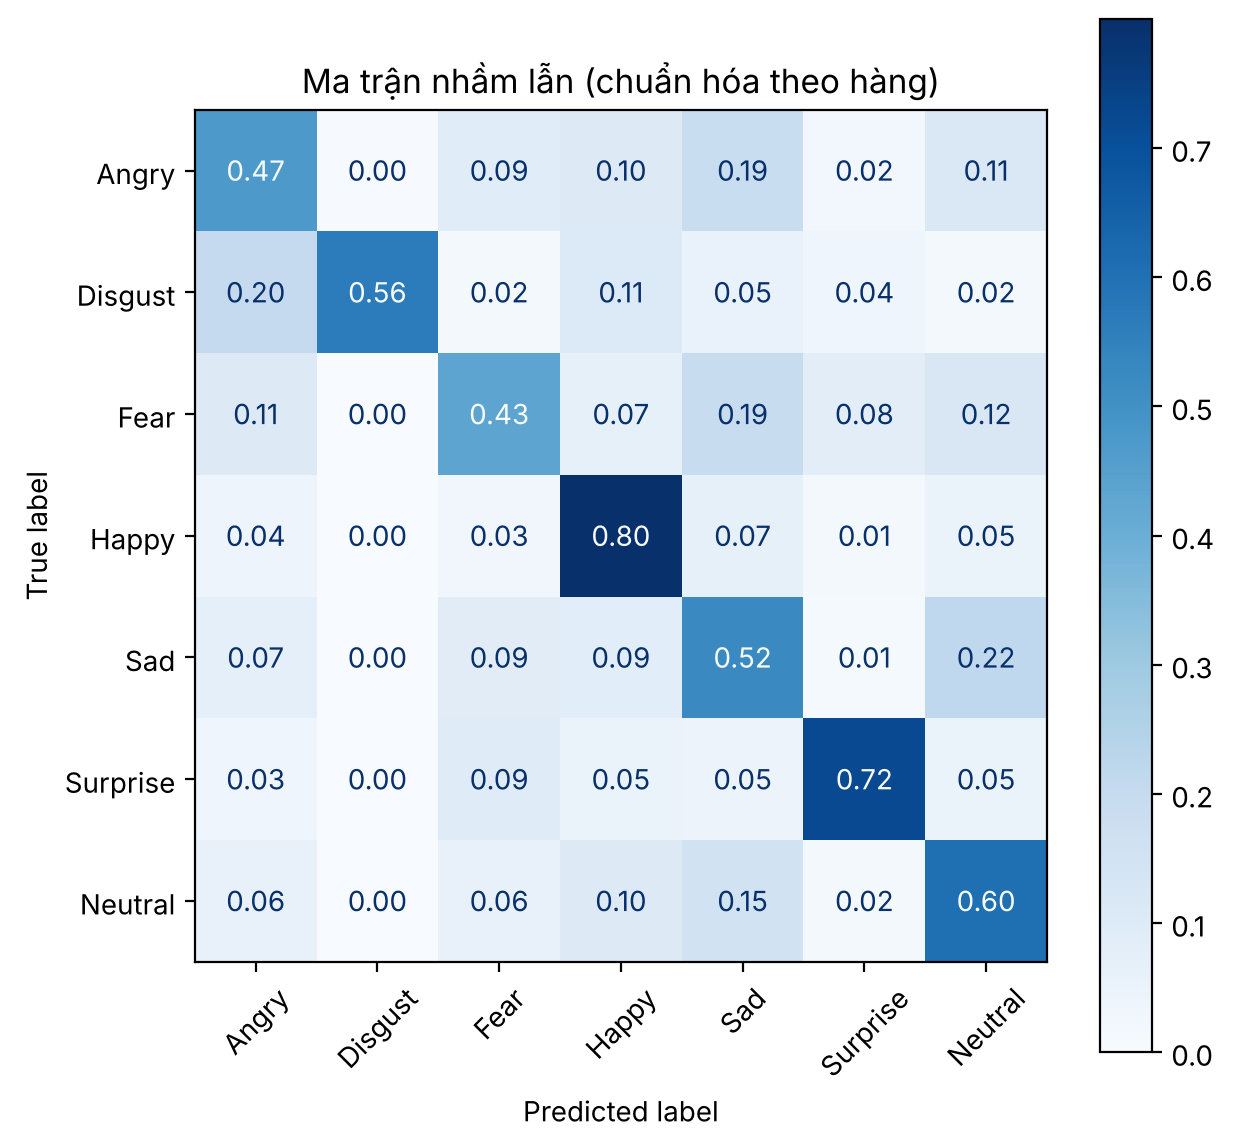

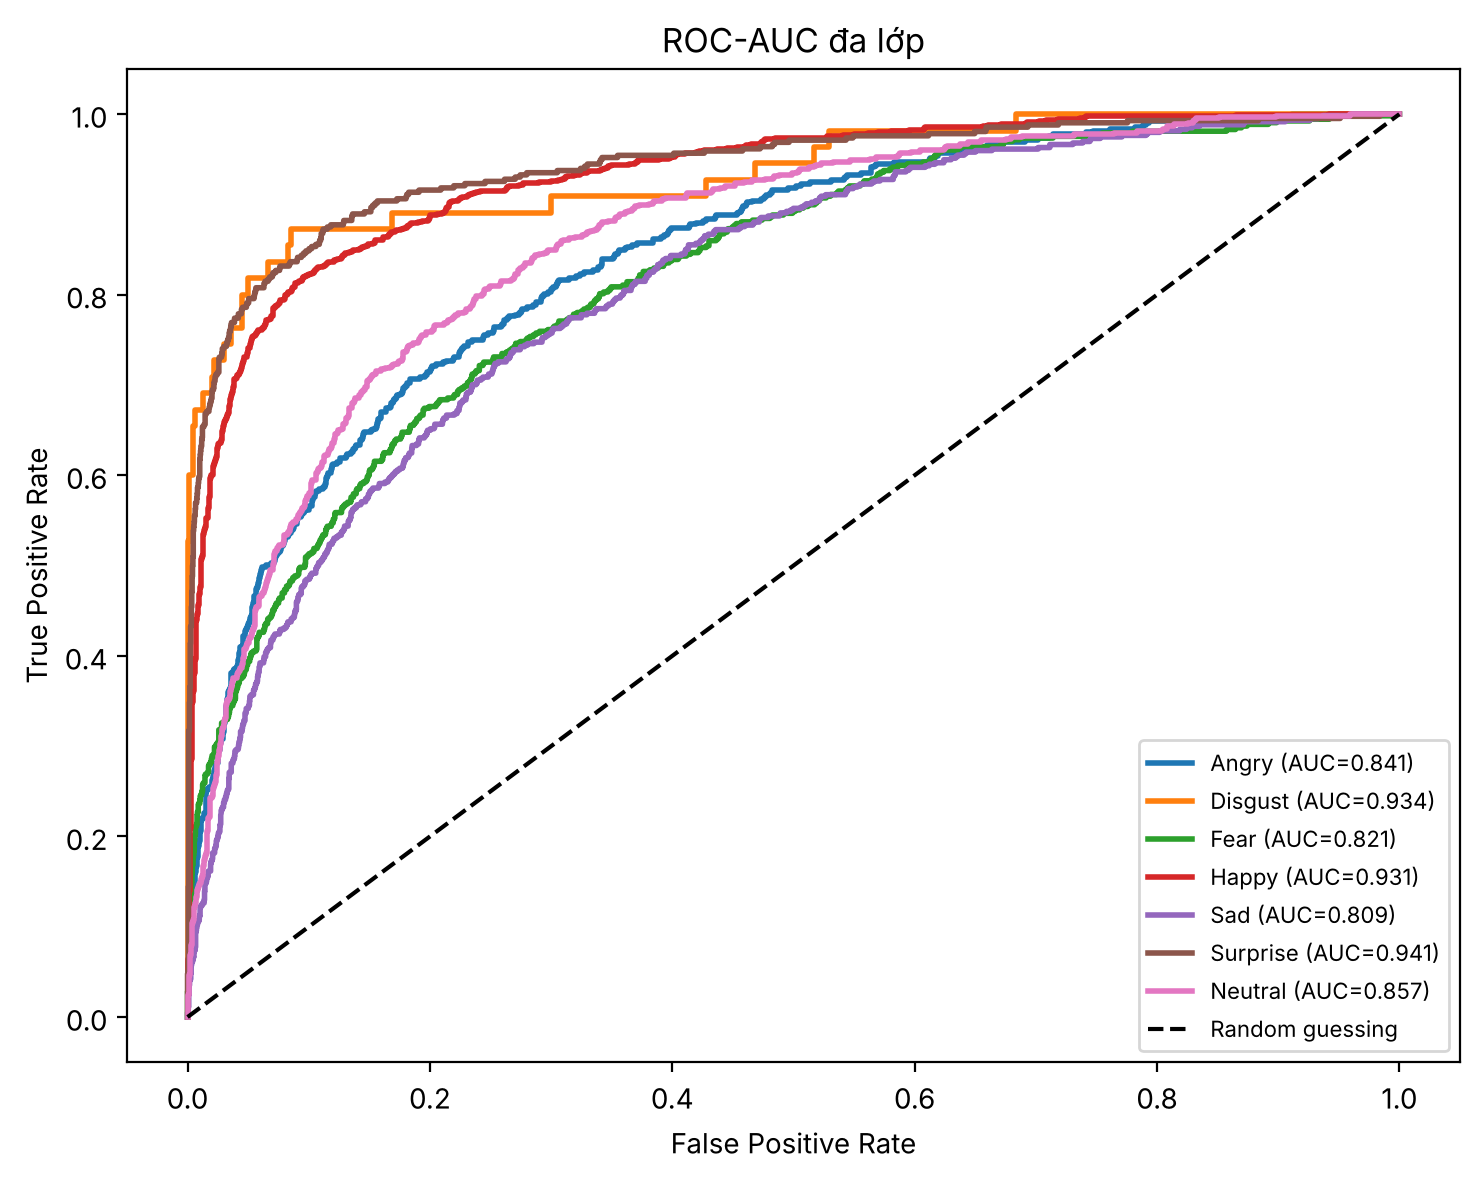

ROC-AUC micro: 0.8931 | macro: 0.8764


In [7]:
# Báo cáo chi tiết cho cấu hình dùng thật: ensemble (+ flip-TTA nếu USE_TTA)
p_final = probs['ENSEMBLE']
y_prob = (p_final['orig'] + p_final['flip']) / 2.0 if USE_TTA else p_final['orig']
y_pred = y_prob.argmax(1)
print('Cấu hình: ensemble{}'.format(' + flip-TTA' if USE_TTA else ''))
print('Test accuracy: {:.4f}'.format(np.mean(y_pred == y_test)))
print(classification_report(y_test, y_pred, target_names=LABELS, digits=3))

cm = confusion_matrix(y_test, y_pred, normalize='true')
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='.2f')
plt.title('Ma trận nhầm lẫn (chuẩn hóa theo hàng)')
plt.tight_layout(); plt.show()

# ROC-AUC đa lớp theo chiến lược One-vs-Rest
y_bin = np.eye(NUM_CLASSES)[y_test]
fig, ax = plt.subplots(figsize=(7.5, 6))
for class_idx, class_name in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_prob[:, class_idx])
    ax.plot(fpr, tpr, lw=2, label='{} (AUC={:.3f})'.format(class_name, auc(fpr, tpr)))
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random guessing')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC-AUC đa lớp')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('ROC-AUC micro: {:.4f} | macro: {:.4f}'.format(
    roc_auc_score(y_bin, y_prob, average='micro'), roc_auc_score(y_bin, y_prob, average='macro')))

**Nhận xét khi viết báo cáo:** Happy và Surprise là hai lớp dễ nhất, Sad, Fear và Angry hay bị nhầm lẫn với nhau và với Neutral (xem ma trận nhầm lẫn). Đây là đặc điểm chung của FER2013 (ảnh xám 48x48, độ phân giải thấp, nhãn có nhiễu), và mô hình tốt thường chỉ đạt khoảng 65–72% trên tập này.

## 4. Ảnh upload vào demo

**Ảnh nên dùng:** mặt rõ, nhìn thẳng hoặc nghiêng nhẹ (dưới khoảng 30°), vùng mặt tối thiểu khoảng 100x100 px, đủ sáng, không bị che (khẩu trang, kính đen, tay, tóc phủ mắt), biểu cảm rõ ràng, tốt nhất 1 mặt/ảnh, định dạng jpg/png.

**Kiểm tra đầu vào trong code:**
- Không tìm thấy mặt → báo «không tìm thấy khuôn mặt»; mặt quá nhỏ → báo «mặt quá nhỏ».
- Ảnh quá tối, cháy sáng hoặc mờ → cảnh báo. Các chỉ số này được đo **trên vùng mặt đã cắt**, không đo trên cả ảnh, để ảnh nền trắng không bị báo nhầm là cháy sáng.
- Nhiều khuôn mặt → cảnh báo và chỉ dùng mặt lớn nhất.

In [8]:
def _find_cascade():
    name = 'haarcascade_frontalface_default.xml'
    for p in (os.path.join(getattr(cv2.data, 'haarcascades', ''), name), name):
        if os.path.exists(p):
            return p
    url = 'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/' + name
    print('Chưa có', name, '- đang tải từ GitHub...')
    urllib.request.urlretrieve(url, name)
    return name

face_cascade = cv2.CascadeClassifier(_find_cascade())
assert not face_cascade.empty(), 'Không nạp được haarcascade_frontalface_default.xml'


def decode_image(data, filename):
    '''Kiểm tra định dạng, dung lượng và giải mã ảnh. Trả về (ảnh BGR, thông báo lỗi).'''
    if not filename.lower().endswith(ALLOWED_EXT):
        return None, 'Định dạng không hỗ trợ, chỉ nhận ảnh jpg/png.'
    if len(data) / (1024 * 1024) > MAX_FILE_MB:
        return None, 'Ảnh lớn hơn {} MB, hãy dùng ảnh nhỏ hơn.'.format(MAX_FILE_MB)
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        return None, 'Không đọc được ảnh, file có thể bị hỏng.'
    return img, None


def remove_overlapping_faces(boxes, iou_threshold=0.30):
    '''Loại ô Haar trùng nhau và giữ một ô đại diện.'''
    boxes = sorted((tuple(map(int, b)) for b in boxes), key=lambda b: b[2] * b[3], reverse=True)
    kept = []
    for x1, y1, w1, h1 in boxes:
        duplicate = False
        for x2, y2, w2, h2 in kept:
            iw = max(0, min(x1 + w1, x2 + w2) - max(x1, x2))
            ih = max(0, min(y1 + h1, y2 + h2) - max(y1, y2))
            inter = iw * ih
            union = w1 * h1 + w2 * h2 - inter
            if union > 0 and inter / union >= iou_threshold:
                duplicate = True
                break
        if not duplicate:
            kept.append((x1, y1, w1, h1))
    return kept


def analyze_image(img_bgr):
    '''Detect mặt, kiểm tra chất lượng vùng mặt, tiền xử lý và dự đoán cảm xúc.'''
    result = {'ok': False, 'error': None, 'warnings': [], 'box': None, 'probs': None, 'label': None}
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # --- Detect mặt trên bản thu nhỏ (nếu ảnh lớn), rồi quy đổi tọa độ về ảnh gốc ---
    scale = min(1.0, DETECT_MAX_SIDE / max(gray.shape))
    small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale < 1.0 else gray
    faces = face_cascade.detectMultiScale(small, scaleFactor=1.05, minNeighbors=7, minSize=(30, 30))
    faces = [tuple(int(round(v / scale)) for v in b) for b in remove_overlapping_faces(faces)]

    if len(faces) == 0:
        result['error'] = 'Không tìm thấy khuôn mặt.'
        return result

    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    result['box'] = (x, y, w, h)
    if min(w, h) < MIN_FACE_SIZE:
        result['error'] = 'Mặt quá nhỏ ({}x{} px), hãy dùng ảnh gần hơn.'.format(w, h)
        return result
    if len(faces) > 1:
        result['warnings'].append('Có {} khuôn mặt phát hiện, chỉ dùng mặt lớn nhất (nên dùng 1 mặt/ảnh).'.format(len(faces)))

    # Mở rộng nhẹ quanh khuôn mặt để tránh cắt mép mắt/mũi/môi
    mx, my = int(w * FACE_MARGIN_X), int(h * FACE_MARGIN_Y)
    x1, y1 = max(0, x - mx), max(0, y - my)
    x2, y2 = min(gray.shape[1], x + w + mx), min(gray.shape[0], y + h + my)
    face_gray = gray[y1:y2, x1:x2]

    # --- Kiểm tra ánh sáng và độ nét TRÊN VÙNG MẶT ---
    brightness = float(face_gray.mean())
    if brightness < DARK_THRESHOLD:
        result['warnings'].append('Cảnh báo: mặt quá tối, ánh sáng không đủ.')
    elif brightness > BRIGHT_THRESHOLD:
        result['warnings'].append('Cảnh báo: mặt quá sáng hoặc cháy sáng.')
    face_ref = cv2.resize(face_gray, (96, 96), interpolation=cv2.INTER_AREA)
    if cv2.Laplacian(face_ref, cv2.CV_64F).var() < BLUR_THRESHOLD:
        result['warnings'].append('Cảnh báo: mặt có vẻ bị mờ, kết quả có thể kém chính xác.')

    # --- Dự đoán, có thể kèm Test-Time Augmentation (ảnh gốc + ảnh lật ngang) ---
    batch = [preprocess_gray_face(face_gray)]
    if USE_TTA:
        batch.append(preprocess_gray_face(cv2.flip(face_gray, 1)))
    probs = model.predict(np.stack(batch), verbose=0).mean(axis=0)

    idx = int(np.argmax(probs))
    if probs[idx] < LOW_CONFIDENCE:
        result['warnings'].append('Độ tin cậy thấp, biểu cảm có thể quá nhẹ hoặc mơ hồ.')
    result.update(ok=True, probs=probs, label=idx)
    return result


def analyze_path(path):
    with open(path, 'rb') as f:
        data = f.read()
    img, err = decode_image(data, os.path.basename(path))
    if err:
        return None, {'ok': False, 'error': err, 'warnings': [], 'box': None, 'probs': None, 'label': None}
    return img, analyze_image(img)


def show_result(img_bgr, result):
    for w in result['warnings']:
        print(w)
    if not result['ok']:
        print('Lỗi:', result['error'])

    vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    if result['box'] is not None:
        x, y, w, h = result['box']
        color = (0, 200, 0) if result['ok'] else (220, 0, 0)
        cv2.rectangle(vis, (x, y), (x + w, y + h), color, max(2, vis.shape[1] // 200))

    if result['ok']:
        probs, idx = result['probs'], result['label']
        print('Kết quả: {}  {} ({}) - độ tin cậy {:.1%}'.format(EMOJIS[idx], LABELS[idx], LABELS_VI[idx], probs[idx]))
        fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1, 1.1]})
        axes[0].imshow(vis); axes[0].set_title('{} ({})'.format(LABELS[idx], LABELS_VI[idx])); axes[0].axis('off')
        bars = axes[1].barh(LABELS, probs)
        bars[idx].set_color('tab:green')
        axes[1].set_xlim(0, 1); axes[1].invert_yaxis(); axes[1].set_title('Xác suất từng cảm xúc')
        plt.tight_layout(); plt.show()
        plt.close(fig)   # tránh vẽ lặp hình trong Output widget
    else:
        fig = plt.figure(figsize=(4, 4)); plt.imshow(vis); plt.axis('off'); plt.show()
        plt.close(fig)

print('Sẵn sàng demo.')

Sẵn sàng demo.


### 4.1 Demo bằng nút upload hoặc ảnh đã copy

Chọn file JPG/PNG bằng nút **Chọn ảnh**, hoặc copy ảnh trong máy rồi nhấn **Lấy ảnh đã copy** (nút này dùng Clipboard của Windows/macOS, không hoạt động trên Linux).

In [9]:
import io
import ipywidgets as widgets
from PIL import Image, ImageGrab
from IPython.display import clear_output

uploader = widgets.FileUpload(accept='.jpg,.jpeg,.png', multiple=False, description='Chọn ảnh')
clipboard_button = widgets.Button(description='Lấy ảnh đã copy', icon='clipboard', button_style='primary')
out = widgets.Output()


def process_image_bytes(data, name):
    out.clear_output(wait=True)   # xóa kết quả cũ trước khi in kết quả mới
    with out:
        print('Ảnh:', name)
        img, err = decode_image(data, name)
        if err:
            print('Lỗi:', err)
            return
        show_result(img, analyze_image(img))


def on_upload(change):
    value = uploader.value
    items = value.values() if isinstance(value, dict) else value
    for item in items:
        process_image_bytes(bytes(item['content']), item['name'])


def on_clipboard_click(_):
    out.clear_output(wait=True)
    with out:
        try:
            clip = ImageGrab.grabclipboard()
            if isinstance(clip, list):
                if not clip:
                    print('Clipboard không chứa ảnh.')
                    return
                clip = Image.open(clip[0])
            if clip is None:
                print('Clipboard không chứa ảnh. Hãy copy ảnh, rồi nhấn nút lại.')
                return
            if clip.mode not in ('RGB', 'RGBA'):
                clip = clip.convert('RGB')
            buffer = io.BytesIO()
            clip.save(buffer, format='PNG')
            process_image_bytes(buffer.getvalue(), 'clipboard.png')
        except Exception as exc:
            print('Không đọc được Clipboard:', exc)


uploader.observe(on_upload, names='value')
clipboard_button.on_click(on_clipboard_click)
display(widgets.HBox([uploader, clipboard_button]), out)

### 4.2 Demo bằng đường dẫn file

Có 2 khuôn mặt phát hiện, chỉ dùng mặt lớn nhất (nên dùng 1 mặt/ảnh).
Kết quả: 😄  Happy (Vui) - độ tin cậy 86.8%


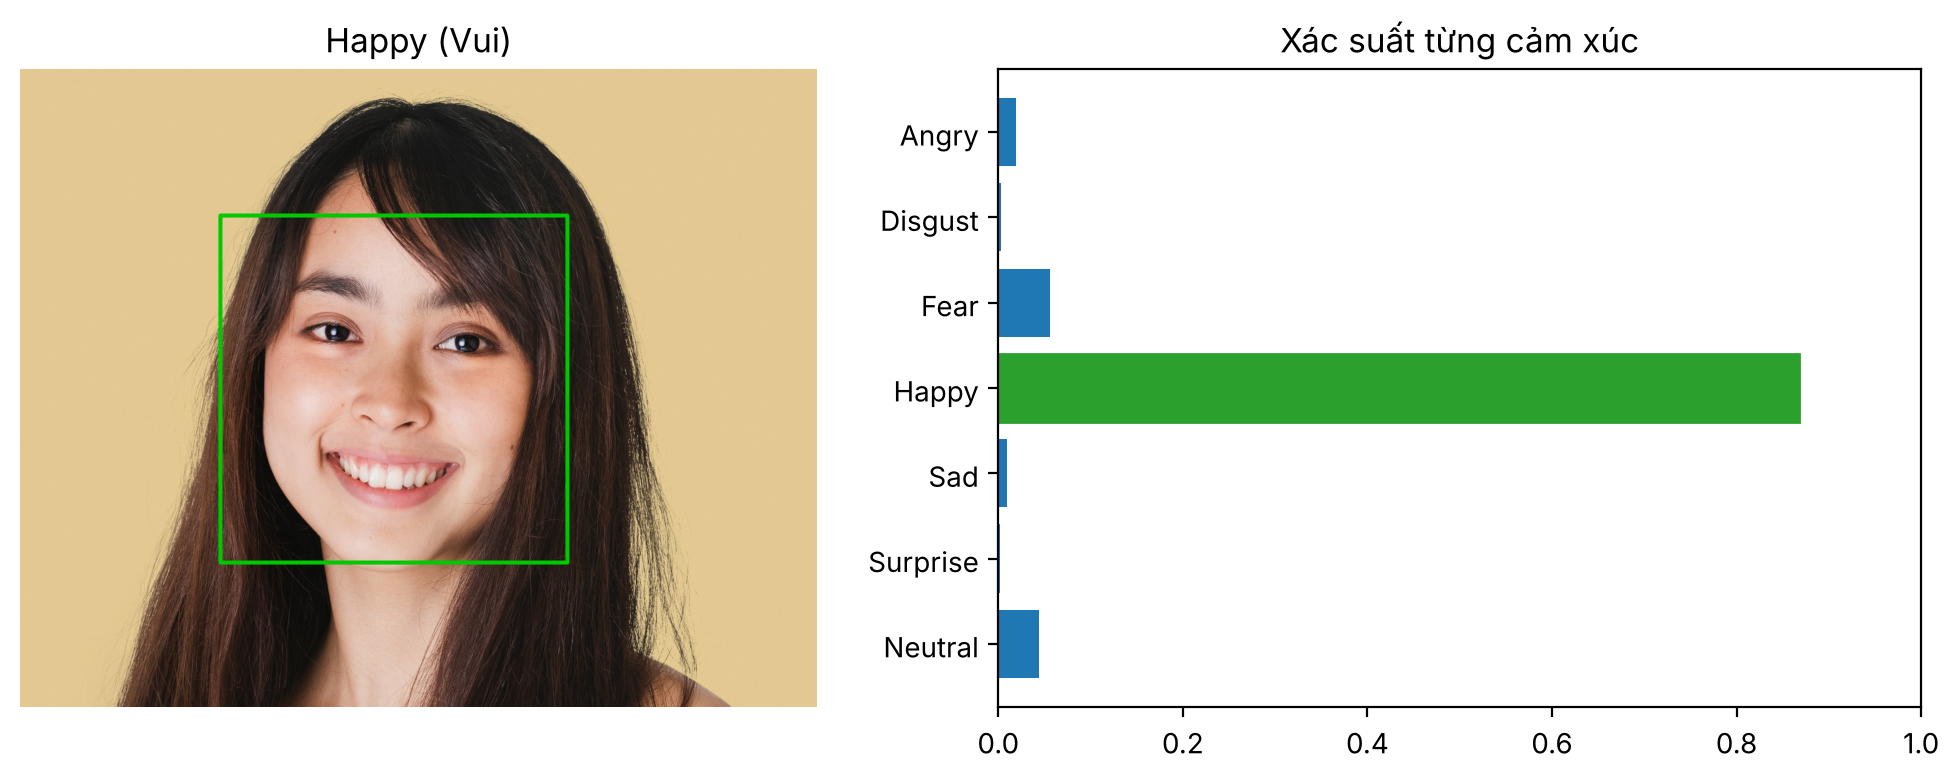

In [10]:
IMAGE_PATH = os.path.join(TEST_DIR, 'vui_1.jpg')   # đổi thành đường dẫn ảnh của bạn

img, res = analyze_path(IMAGE_PATH)
if img is None:
    print('Lỗi:', res['error'])
else:
    show_result(img, res)

## 5. Ảnh test cho báo cáo

Chuẩn bị **10–15 ảnh** bỏ vào thư mục `test_images/`:

- **Vài ảnh chuẩn** (mặt thẳng, sáng, biểu cảm rõ) → `difficulty = easy`.
- **Vài ảnh khó** (nghiêng, thiếu sáng, đeo kính hoặc khẩu trang, mặt nhỏ) để làm phần «điểm chưa đạt» → `difficulty = hard`.

File `test_labels.csv` có 4 cột: `filename`, `true_label` (một trong: Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral), `difficulty` (easy/hard), `note`. Nếu chưa có file này, cell dưới sẽ tự tạo file mẫu để bạn điền nhãn.

In [11]:
os.makedirs(TEST_DIR, exist_ok=True)

if not os.path.exists(TEST_CSV):
    files = sorted(f for f in os.listdir(TEST_DIR) if f.lower().endswith(ALLOWED_EXT))
    pd.DataFrame({'filename': files, 'true_label': '', 'difficulty': 'easy', 'note': ''}).to_csv(TEST_CSV, index=False)
    print('Đã tạo file mẫu', TEST_CSV, '- hãy điền true_label/difficulty/note rồi chạy lại cell này.')
else:
    meta = pd.read_csv(TEST_CSV).fillna('')
    if not 10 <= len(meta) <= 15:
        print('Lưu ý: hiện có {} ảnh, nên chuẩn bị 10-15 ảnh.'.format(len(meta)))
    if 'hard' not in set(meta['difficulty']):
        print('Lưu ý: chưa có ảnh khó (difficulty = hard); nên thêm vài ảnh khó cho phần «điểm chưa đạt».')
    missing = sorted(set(LABELS) - set(meta['true_label']))
    if missing:
        print('Lưu ý: chưa có ảnh cho nhãn:', ', '.join(missing))

    rows, images = [], []
    for _, r in meta.iterrows():
        img, res = analyze_path(os.path.join(TEST_DIR, r['filename']))
        images.append((img, res))
        if res['ok']:
            pred, conf, status = LABELS[res['label']], float(res['probs'][res['label']]), 'OK'
        else:
            pred, conf, status = '', 0.0, res['error']
        rows.append({
            'filename': r['filename'], 'difficulty': r['difficulty'], 'true_label': r['true_label'],
            'predicted': pred, 'confidence': round(conf, 3),
            'correct': bool(res['ok'] and pred == r['true_label']),
            'status': status, 'warnings': ' | '.join(res['warnings']), 'note': r['note'],
        })

    report = pd.DataFrame(rows)
    report.to_csv('ket_qua_test.csv', index=False)
    display(report)

    print('\nĐộ chính xác chung: {:.1%} ({}/{})'.format(report['correct'].mean(), report['correct'].sum(), len(report)))
    print('\nĐộ chính xác theo mức độ khó (ảnh không detect được mặt tính là sai):')
    display(report.groupby('difficulty')['correct'].agg(['mean', 'sum', 'count']))

Lưu ý: chưa có ảnh khó (difficulty = hard); nên thêm vài ảnh khó cho phần «điểm chưa đạt».
Lưu ý: chưa có ảnh cho nhãn: Disgust, Fear


,filename,difficulty,true_label,predicted,confidence,correct,status,warnings,note
0,neutral1.jpg,easy,Neutral,Neutral,0.960,True,OK,,biểu cảm trung tính
1,neutral2.jpg,easy,Neutral,Neutral,0.923,True,OK,,biểu cảm trung tính
2,neutral3.jpg,easy,Neutral,Neutral,0.673,True,OK,,biểu cảm trung tính
3,sad1.jpg,easy,Sad,Neutral,0.616,False,OK,,biểu cảm buồn
4,sad2.jpg,easy,Sad,Happy,0.371,False,OK,"Độ tin cậy thấp, biểu cảm có thể quá nhẹ hoặc ...",biểu cảm buồn
5,sad3.jpg,easy,Sad,Neutral,0.503,False,OK,"Có 2 khuôn mặt phát hiện, chỉ dùng mặt lớn nhấ...",biểu cảm buồn
6,surprise1.jpg,easy,Surprise,Surprise,0.973,True,OK,,biểu cảm ngạc nhiên
7,surprise2.jpg,easy,Surprise,Surprise,0.778,True,OK,,biểu cảm ngạc nhiên
8,surprise3.jpg,easy,Surprise,Surprise,0.712,True,OK,,biểu cảm ngạc nhiên
9,tucgian1.jpg,easy,Angry,Angry,0.926,True,OK,"Có 2 khuôn mặt phát hiện, chỉ dùng mặt lớn nhấ...",biểu cảm tức giận



Độ chính xác chung: 80.0% (12/15)

Độ chính xác theo mức độ khó (ảnh không detect được mặt tính là sai):


,mean,sum,count
difficulty,,,
easy,0.8,12,15


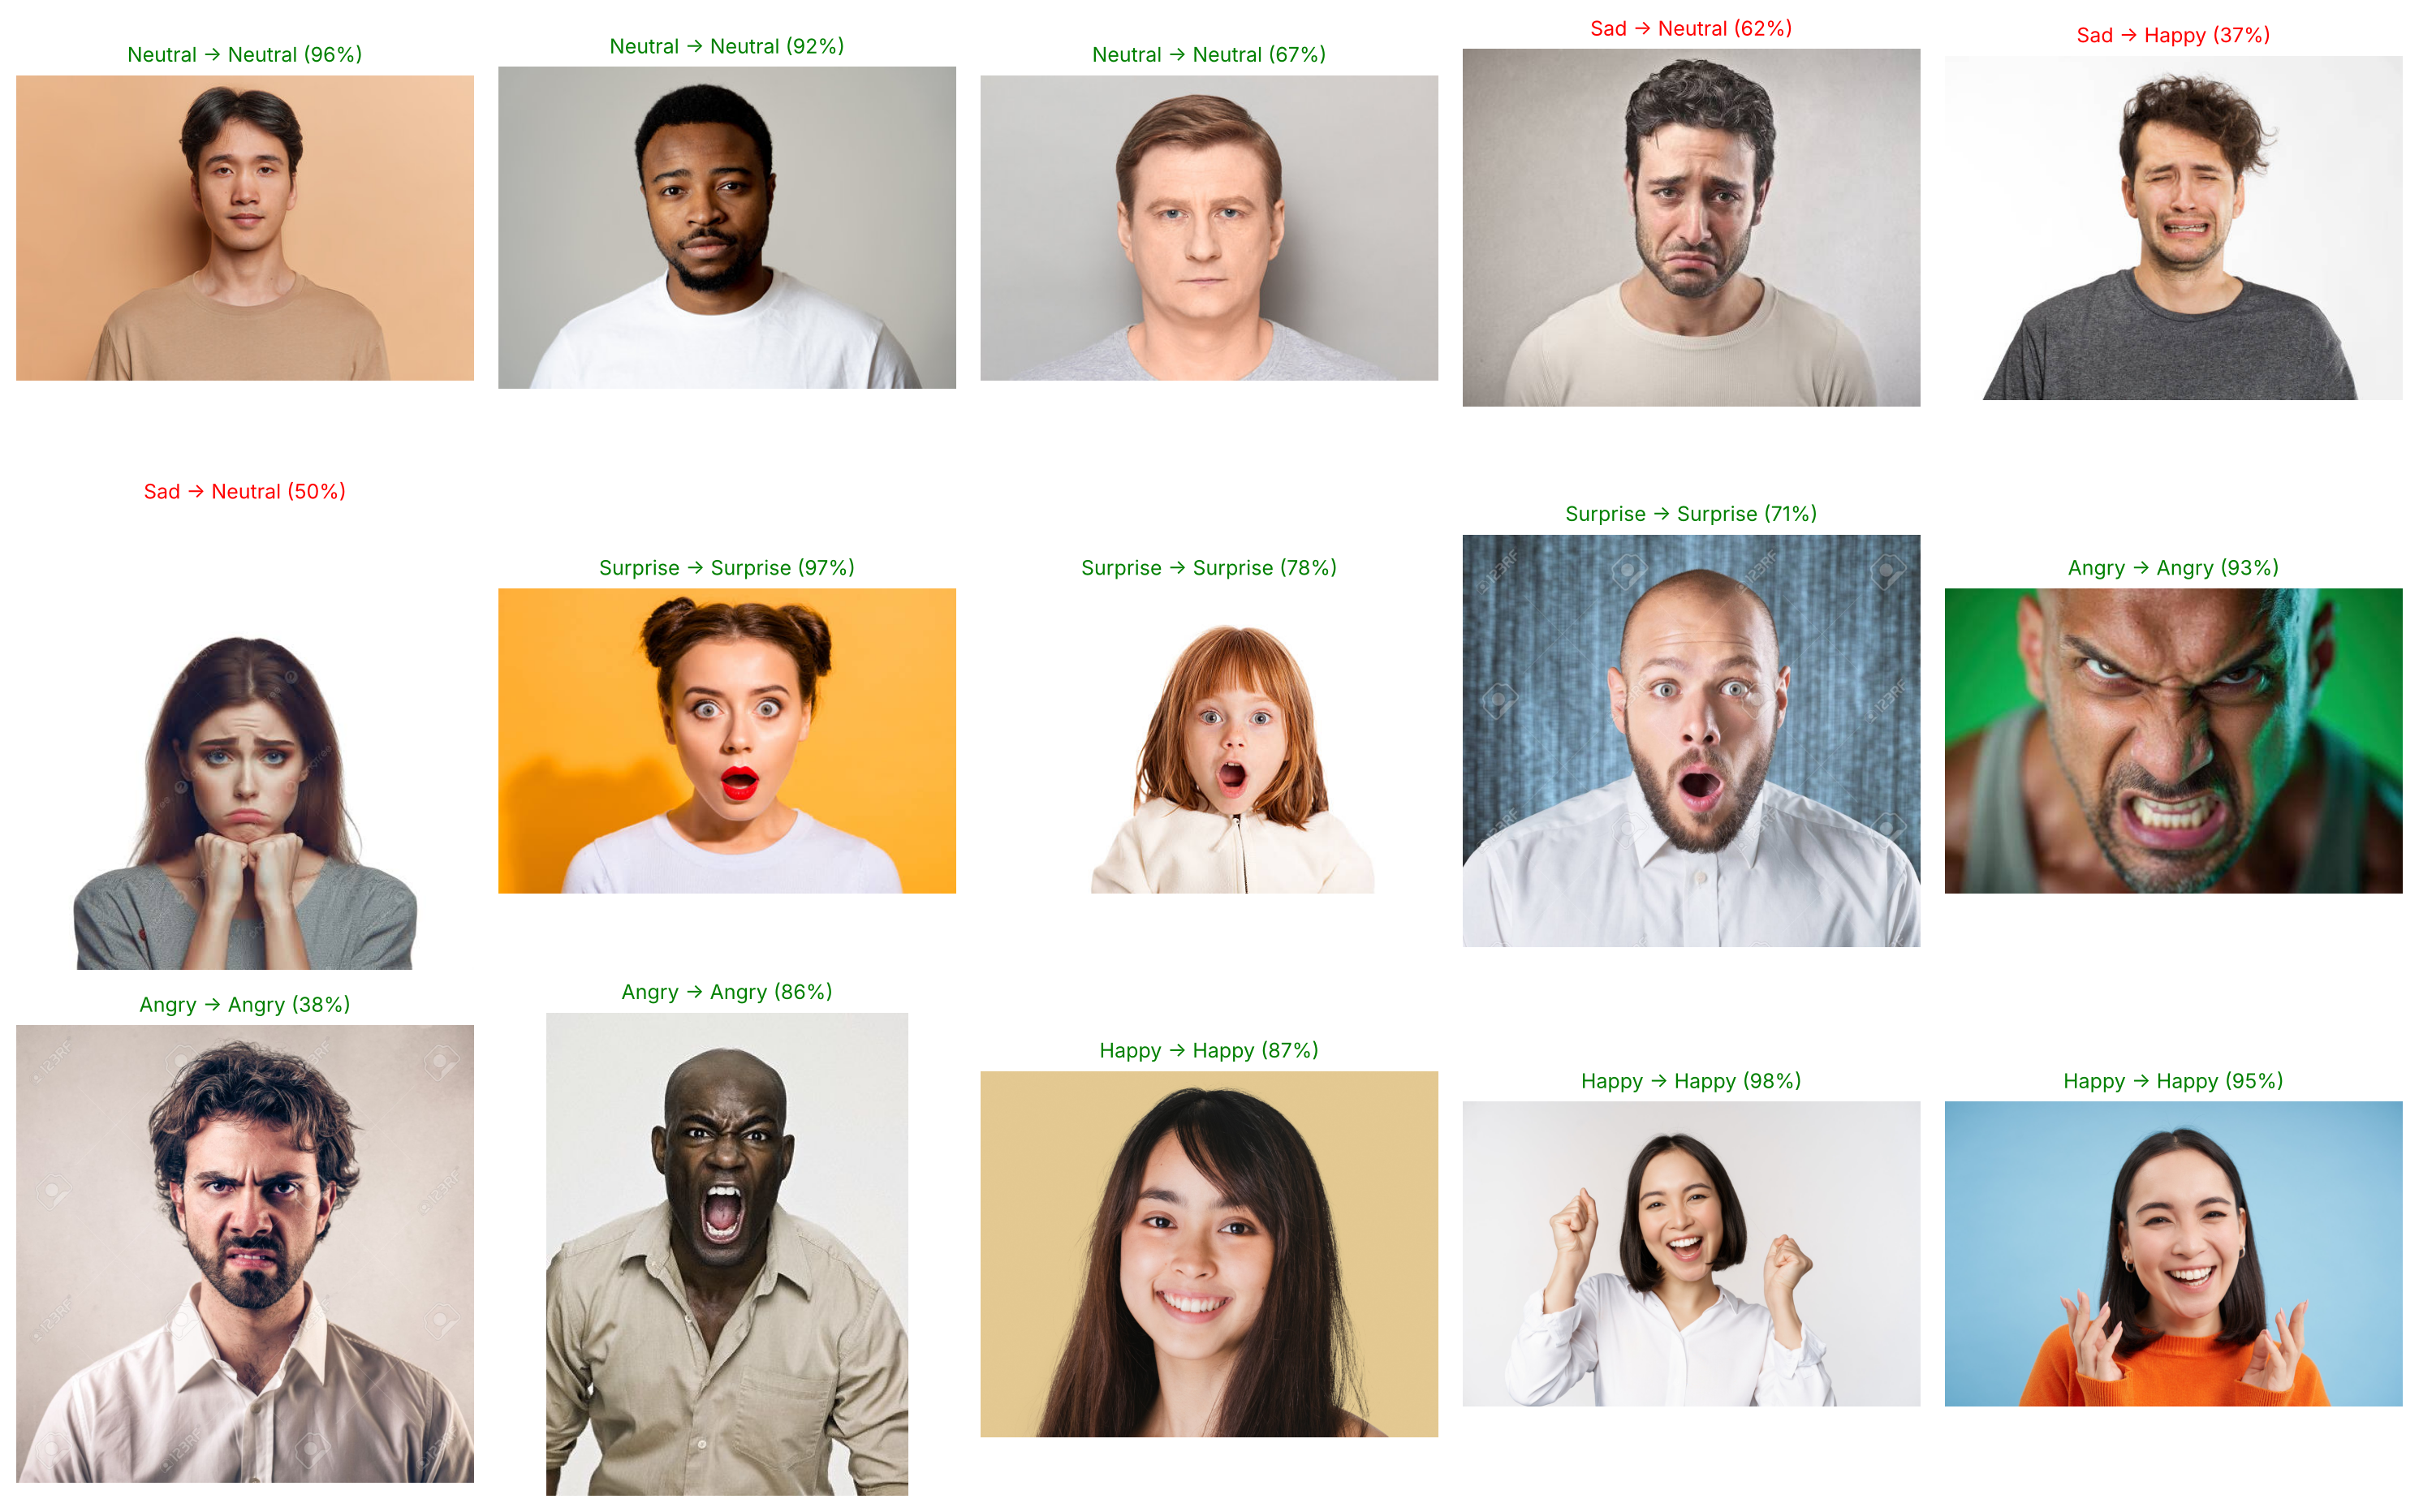

,filename,difficulty,true_label,predicted,confidence,status,note
3,sad1.jpg,easy,Sad,Neutral,0.616,OK,biểu cảm buồn
4,sad2.jpg,easy,Sad,Happy,0.371,OK,biểu cảm buồn
5,sad3.jpg,easy,Sad,Neutral,0.503,OK,biểu cảm buồn


In [12]:
# Lưới ảnh test: tiêu đề xanh = đúng, đỏ = sai (dùng làm hình trong báo cáo)
n = len(images)
cols = 5
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(3 * cols, 3.2 * rows_n))
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis('off')
for ax, (img, res), (_, row) in zip(axes, images, report.iterrows()):
    if img is not None:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    title = ('{} → {} ({:.0%})'.format(row['true_label'], row['predicted'], row['confidence'])
             if res['ok'] else '{} → lỗi'.format(row['true_label']))
    ax.set_title(title, fontsize=9, color='green' if row['correct'] else 'red')
plt.tight_layout()
plt.show()

# Các ảnh sai: dùng cho mục «điểm chưa đạt» trong báo cáo
display(report[~report['correct']][['filename', 'difficulty', 'true_label', 'predicted', 'confidence', 'status', 'note']])

### Ghi chú cho mục «điểm chưa đạt» trong báo cáo

Với mỗi ảnh sai, nên giải thích nguyên nhân:

- Mặt nghiêng nhiều hoặc cúi → bước detect mặt (Haar) hay trượt.
- Mặt quá nhỏ (vài chục px) → cả detect lẫn mô hình đều kém.
- Ngược sáng, quá tối hoặc cháy sáng → mất chi tiết khuôn mặt.
- Khẩu trang, kính đen, tay che miệng, tóc phủ mắt → mô hình đoán sai.
- Biểu cảm nhẹ hoặc mơ hồ → thường bị đoán thành Neutral; Sad, Fear và Angry vốn là các lớp khó của FER2013.
- Ảnh train FER2013 chỉ 48x48 xám, độ phân giải thấp và nhãn có nhiễu; ảnh demo là ảnh studio nên có thể khác phân phối với dữ liệu train.
- Chỉ có 10–15 ảnh test nên mỗi ảnh sai làm accuracy giảm 7–10 điểm; số liệu đáng tin hơn là kết quả trên PrivateTest ở phần 3.

---

### Checklist nhanh

| Loại ảnh | Yêu cầu chính |
|---|---|
| Upload demo | Mặt rõ, lớn (≥100x100 px), đủ sáng, không che, 1 mặt/ảnh |
| Đánh giá (FER2013) | Xám, 48x48, 1 kênh; mô hình tự phóng lên 96x96 và nhân 3 kênh |
| Test báo cáo | 10–15 ảnh, gồm cả ảnh dễ và ảnh khó |